## Plotting evaluation metrics across conversations

The other notebooks in this folder save their results as CSV files in the ```evaluation``` subfolder of each EMISSOR scenario, e.g.:

```
<scenario_id>_likelihood_evaluation.csv
<scenario_id>_llm_judge_evaluation.csv
<scenario_id>_llm_judge_llama_cpp_evaluation.csv
<scenario_id>_manual_evaluation.csv
<scenario_id>_graph_evaluation.csv
```

This notebook uses the ```Plotter``` from ```metrics_plotting.py``` to plot how the scores develop over the turns of the conversations. Each **metric** in the list below is matched as a substring against the CSV filenames. For every numeric column in the matching files (e.g. ```llh``` and ```max_llh``` for ```likelihood```), one plot is made with a line for each conversation. Note that ```llm_judge``` also matches ```llm_judge_llama_cpp```, so the results of both judges are shown in the same plot.

## Prerequisites

This notebook needs ```pandas```, ```matplotlib``` and ```seaborn```, which can be installed through ```pip```:

```
!pip install pandas
!pip install matplotlib
!pip install seaborn
```

In [ ]:
import sys
from pathlib import Path

# Jupyter runs the notebook in its own folder. We add the root of the project to the path,
# so that the modules can be imported from src.cltl.emissor_evaluation
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "cltl").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [1]:
from pathlib import Path
from IPython.display import Image, display
from src.cltl.emissor_evaluation.plots.metrics_plotting import Plotter

## Choosing the scenarios and metrics

Set ```EMISSOR``` to the folder with your scenarios and list the metrics you want to plot. Optionally, set ```COLUMNS``` to a list of column names to plot only those columns, e.g. ```["llh"]``` or ```["Coherent", "Relevant"]```. With ```None``` all numeric columns are plotted.

In [2]:
EMISSOR="/Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor"
SCENARIO="5a55e02f-e2be-4dce-a9b6-bb3c6dba1480"
METRICS = ["likelihood", "llm_judge"]
COLUMNS = None

## Creating the plots

The plots are saved as PNG files in the ```plots``` subfolder of the ```EMISSOR``` folder, named ```<metric>_<column>.png```.

In [3]:
plotter = Plotter()
plotter.plot_conversations(EMISSOR, METRICS, COLUMNS)

Skipping /Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/1af5d56f-638c-495a-92a6-63d5ccd5d6c0/evaluation/1af5d56f-638c-495a-92a6-63d5ccd5d6c0_likelihood_evaluation.csv, it could not be read: No columns to parse from file
/Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/plots/likelihood_llh.png
/Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/plots/likelihood_max_llh.png
/Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/plots/llm_judge_llm_coherence.png


## Showing the plots

The next cell shows the plots that were created for the chosen metrics.

likelihood_llh.png


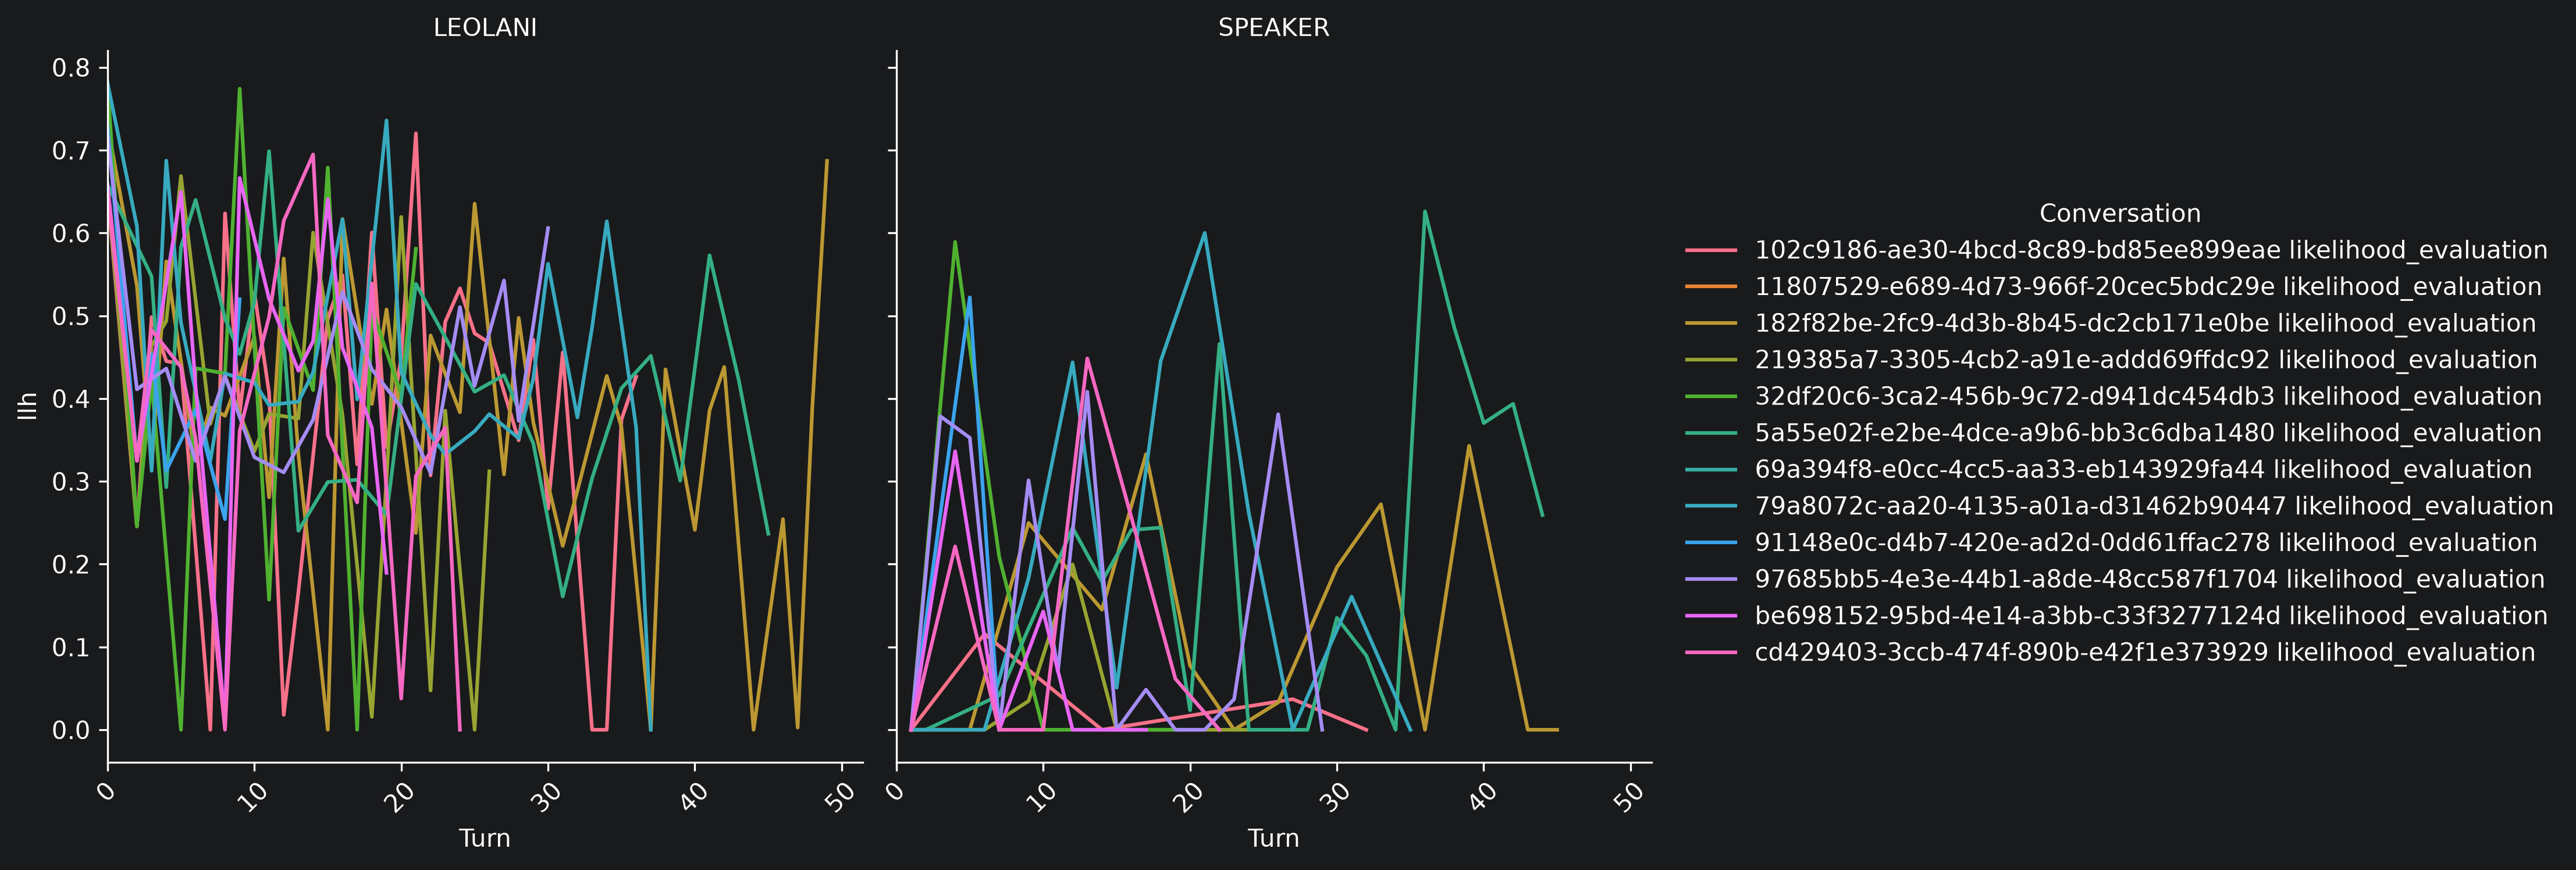

likelihood_max_llh.png


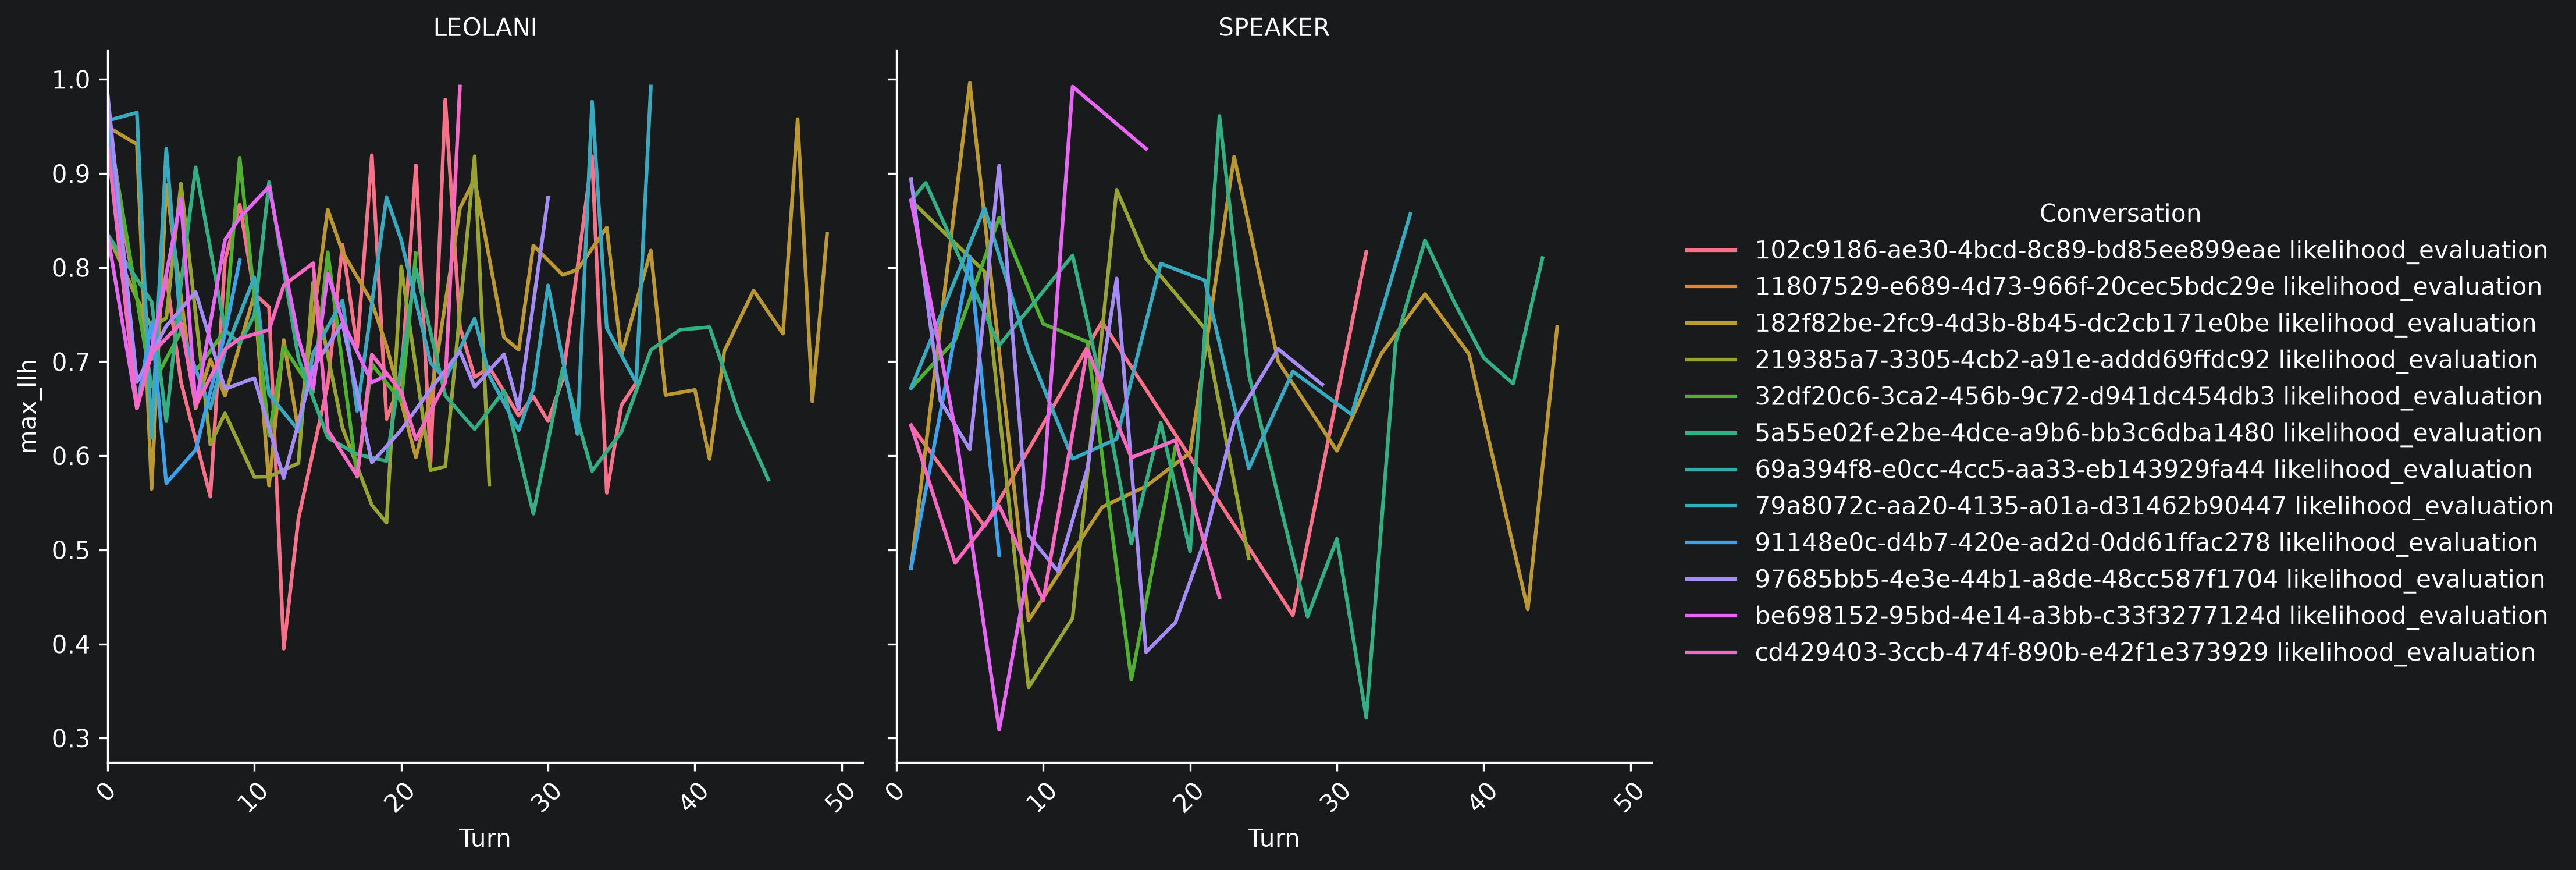

llm_judge_llm_coherence.png


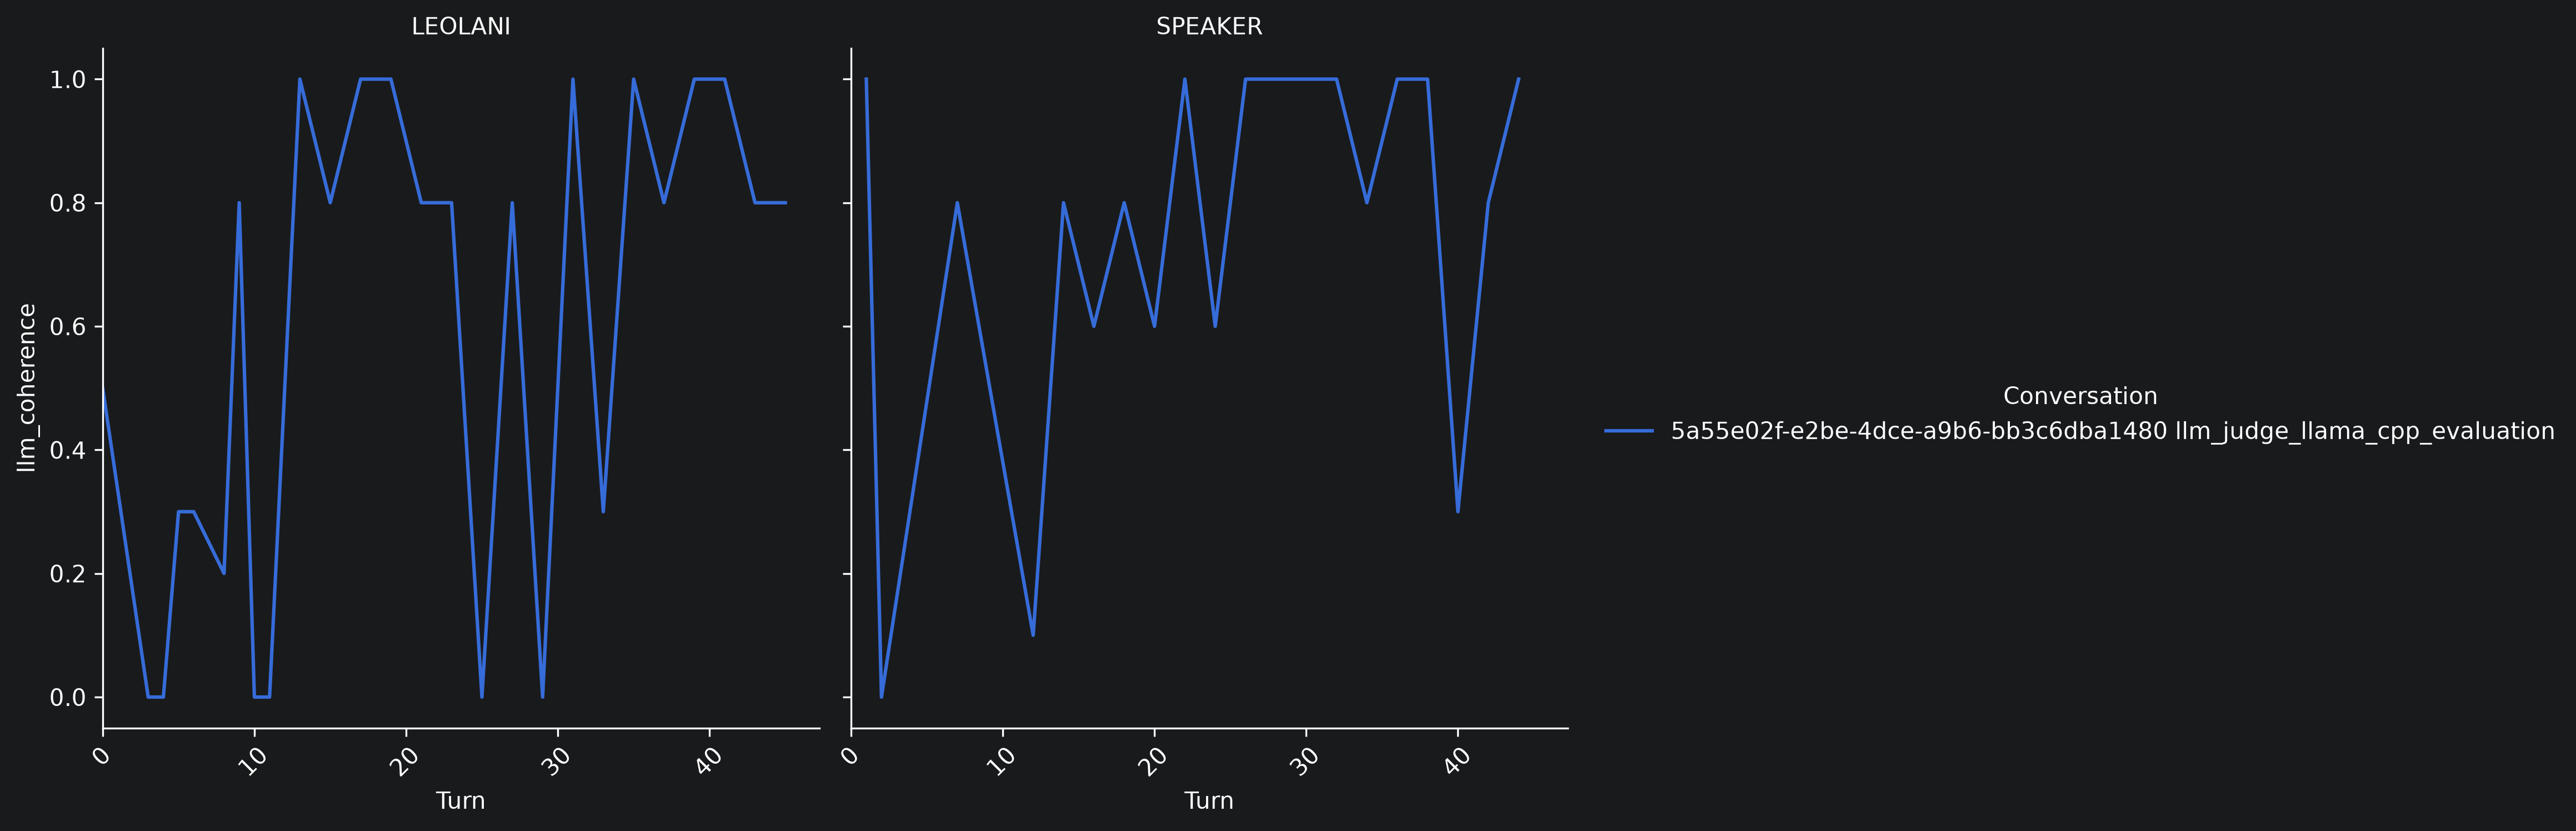

In [4]:
plots_folder = Path(EMISSOR) / "plots"
for metric in METRICS:
    for plot_file in sorted(plots_folder.glob(f"{metric}_*.png")):
        print(plot_file.name)
        display(Image(filename=str(plot_file), width=800))

## Combining metrics for a single scenario

The function ```plot_scenario``` combines all metrics of a single scenario in one plot, with a line for each metric column. Set ```SCENARIO``` to the scenario you want to plot. Use ```normalize=True``` to scale each line to the range 0-1 when the metrics have different scales, e.g. when combining the graph counts with the likelihood and coherence scores.

The plot is saved in the ```evaluation``` subfolder of the scenario as ```<scenario>_<metrics>_combined.png```.

/Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480/evaluation/5a55e02f-e2be-4dce-a9b6-bb3c6dba1480_likelihood_llm_judge_combined.png


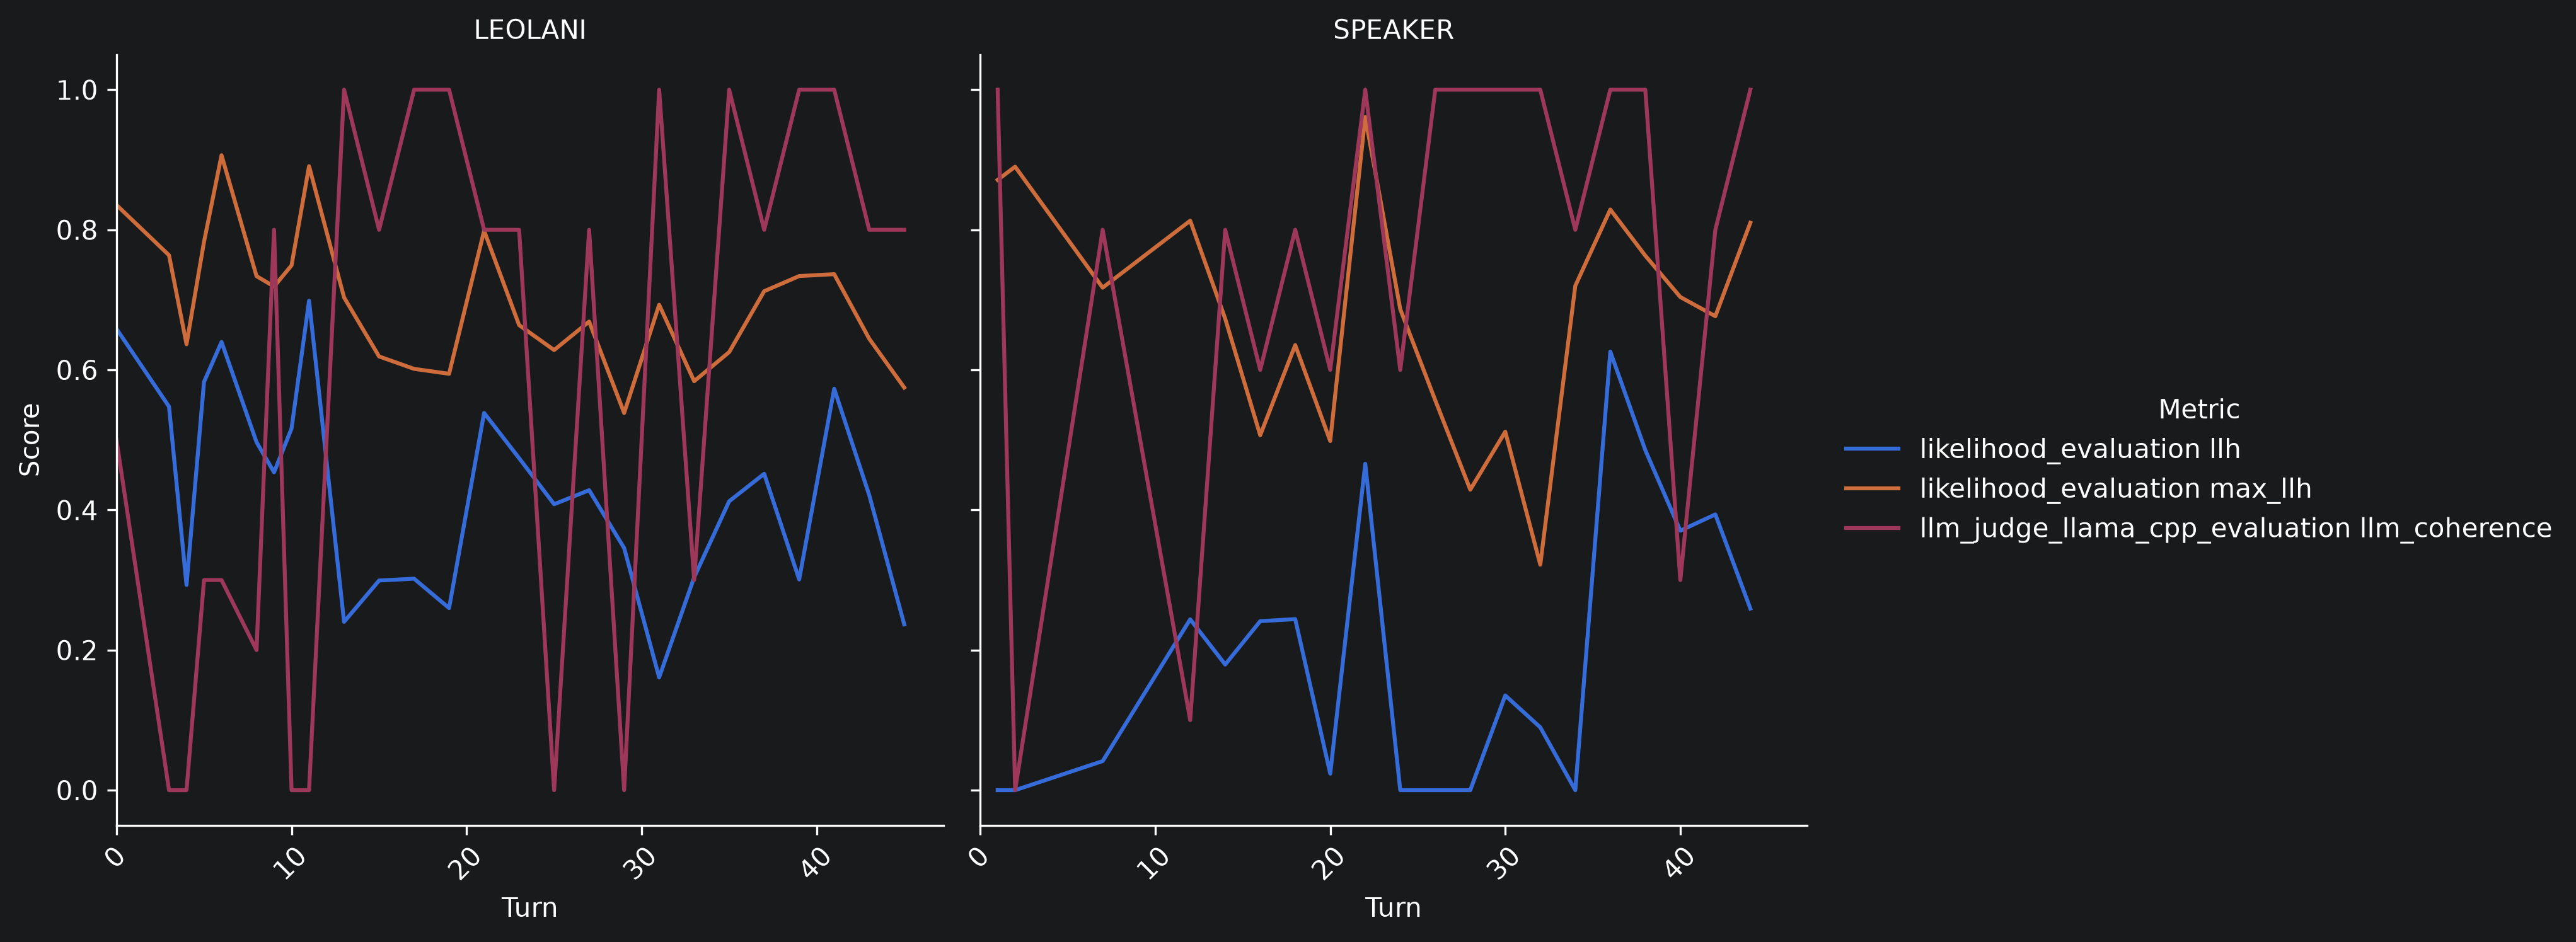

In [5]:
SCENARIO = "5a55e02f-e2be-4dce-a9b6-bb3c6dba1480"
NORMALIZE = False

plotter.plot_scenario(EMISSOR, SCENARIO, METRICS, COLUMNS, normalize=NORMALIZE)

plot_file = Path(EMISSOR) / SCENARIO / "evaluation" / f"{SCENARIO}_{'_'.join(METRICS)}_combined.png"
if plot_file.exists():
    display(Image(filename=str(plot_file), width=800))

## End of notebook